# PharmaML — The Complete Molecule Generation Workflow (Zero to One Hundred)

One notebook, every stage of a *generative* molecular design project, in the
order you would actually run it — the fifth workflow notebook of the series
(after the ML, docking, PK/PD and cell-line ones). Where those four
**analyse** molecules (model them, dock them, compute their pharmacology),
this one **invents** them: the legacy rar archive shipped training scripts
and docking folders, but no code that ever proposed a new structure —
de novo design lived in nobody's repository. This notebook closes that gap
on a laptop CPU: two complementary optimisers, one shared objective library,
one bundled corpus.

| § | Stage | Toolkit |
|---|---|---|
| 0 | **Setup** — imports, scratch directory | — |
| 1 | **The corpus** — 244 curated drug-like SMILES + property landscape | `pharmaml.generative` |
| 2 | **Objectives** — QED, LogP band, TPSA band, MW band, similarity, pharmacophore, novelty | `pharmaml.generative` |
| 3 | **Multi-objective** — weighted geometric mean, one zero vetoes | `pharmaml.generative` |
| 4 | **De novo generation** — the SMILES genetic algorithm | `pharmaml.generative` |
| 5 | **Seeded generation** — start from your own molecules | `pharmaml.generative` |
| 6 | **Lead optimisation** — scaffold-preserving mutation | `pharmaml.generative` |
| 7 | **Reinforcement learning** — char-GRU prior + REINVENT-style fine-tuning | `pharmaml.generative` |
| 8 | **Novelty** — the anti-rediscovery recipe | `pharmaml.generative` |
| 9 | **GA vs RL** — same objective, head-to-head | `pharmaml.generative` |
| 10 | **Publish** — leaderboard CSV + one-click visual bundle | `pharmaml.viz` |
| 11 | **Recap** | — |

Requires RDKit (`pip install 'pharmaml[chem]'`) for the scoring / GA half and
PyTorch (`pip install 'pharmaml[deep]'`) for the RNN / RL half — both are
imported lazily, so importing the subpackage itself needs neither.


## 0 · Setup

Imports, display options and a scratch directory — every artifact this
notebook writes (the ranked leaderboard, the publish bundle) lands under
`WORK`. Nothing else on your machine is touched.

Every generative run in this notebook pins the same `seed`, so re-running
top-to-bottom reproduces the same leaderboards.


In [1]:
import tempfile
from pathlib import Path

import pandas as pd
import rdkit
import torch

from pharmaml import __version__

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 110)

# Scratch directory for this run's artifacts (use any path you like).
WORK = Path(tempfile.mkdtemp(prefix="generative_workflow_"))

# The shipped demo inventory: the §1b seed table loads from examples/data/
# instead of being embedded inline.
DATA_DIR = Path("data")

# One seed for every run in this notebook: reproducible leaderboards.
SEED = 42

print(f"pharmaml {__version__} · rdkit {rdkit.__version__} · torch {torch.__version__}")
print(f"artifacts -> {WORK}")


pharmaml 1.2.86 · rdkit 2026.09.1 · torch 2.14.1+cpu
artifacts -> /tmp/generative_workflow_x817ead4


## 1 · The corpus — what the optimisers build from

`DEFAULT_CORPUS` is the bundled, curated starting point: 244 canonical
drug-like SMILES embedded in the package itself (no data file to lose, no
download to fail). "Curated" means exactly what the cell below checks —
every entry parses, every entry is already in RDKit canonical form, and no
entry is duplicated.

CLI equivalent:

```bash
pharmaml generative corpus --out corpus.csv
```


In [2]:
from pharmaml.generative import DEFAULT_CORPUS

n_unique = len(set(DEFAULT_CORPUS))
print(f"corpus size : {len(DEFAULT_CORPUS)} SMILES")
print(f"unique      : {n_unique}")

pd.DataFrame({"smiles": list(DEFAULT_CORPUS[:10])})


corpus size : 244 SMILES
unique      : 244


,smiles
0,CC(=O)Oc1ccccc1C(=O)O
1,CC(=O)Nc1ccc(O)cc1
2,CC(C)Cc1ccc(C(C)C(=O)O)cc1
3,Cn1c(=O)c2c(ncn2C)n(C)c1=O
4,CN(C)C(=N)N=C(N)N
5,CN1CCCC1c1cccnc1
6,CC(=O)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O
7,CN=C(NC#N)NCCSCc1[nH]cnc1C
8,Cn1cnc2c1c(=O)[nH]c(=O)n2C
9,O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl


Before optimising against a corpus, look at it: the property landscape the
search will explore. `compute_descriptors` turns the 244 SMILES into the
full RDKit descriptor table; `plot_descriptor_distributions` renders the
columns that define "drug-like" — molecular weight, LogP, polar surface,
H-bond donors and acceptors.


244 molecules x 217 descriptors


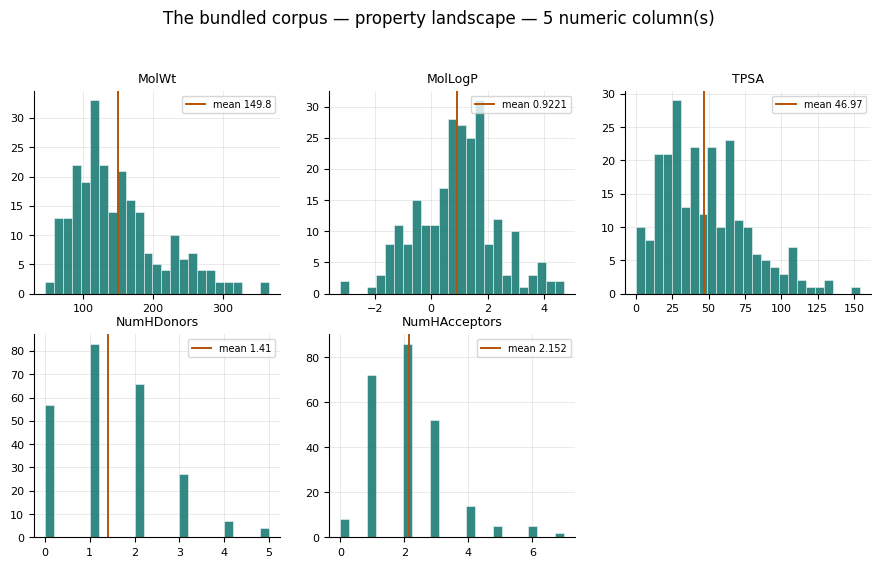

In [3]:
from pharmaml.chem import compute_descriptors
from pharmaml.viz import plot_descriptor_distributions

corpus_desc = compute_descriptors(list(DEFAULT_CORPUS), progress=False)
print(f"{len(corpus_desc)} molecules x {corpus_desc.shape[1] - 1} descriptors")

fig_landscape = plot_descriptor_distributions(
    corpus_desc,
    columns=["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors"],
    title="The bundled corpus — property landscape",
)


## 1b · Your seeds — the "from sample molecules" mode

The optimisers also run **seeded**: hand them a table of your own molecules
and generation 0 starts from those (§5). The demo table below is the
shipped `examples/data/seed_molecules.csv` — 12 named drugs (regenerated
deterministically via `scratch/build_example_data.py`) — point
`SEEDS_CSV` at your own CSV and every cell below runs unchanged.


In [4]:
# --- DEMO SEEDS --------------------------------------------------------
# The 12 named drugs shipped as examples/data/seed_molecules.csv
# (regenerated deterministically by scratch/build_example_data.py).
# (In your project: point SEEDS_CSV at your own molecules instead.)
SEEDS_CSV = DATA_DIR / "seed_molecules.csv"   # <- replace with your own file

seeds = pd.read_csv(SEEDS_CSV)
seed_smiles = seeds["smiles"].tolist()
print(f"{len(seeds)} seed molecules  <-  {SEEDS_CSV}")
seeds


12 seed molecules  <-  data/seed_molecules.csv


,name,smiles
0,aspirin,CC(=O)Oc1ccccc1C(=O)O
1,paracetamol,CC(=O)Nc1ccc(O)cc1
2,ibuprofen,CC(C)Cc1ccc(C(C)C(=O)O)cc1
3,caffeine,Cn1c(=O)c2c(ncn2C)n(C)c1=O
4,metformin,CN(C)C(=N)N=C(N)N
5,nicotine,CN1CCCC1c1cccnc1
6,warfarin,CC(=O)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O
7,theophylline,Cn1cnc2c1c(=O)[nH]c(=O)n2C
8,diclofenac,O=C(O)Cc1ccccc1Nc1c(Cl)cccc1Cl
9,naproxen,COc1ccc2cc(C(C)C(=O)O)ccc2c1


## 2 · The objective library — what "good" means

Every optimiser in this subpackage maximises the same contract: an object
with a `score(smiles) -> float` in `[0, 1]`. The library ships seven
ready-made objectives — the four profile bands and QED below, then
similarity, pharmacophore and novelty in the next cell.

Scoring a small probe set is the fastest way to see what each objective
rewards before you commit a search to it.


In [5]:
from pharmaml.generative import (
    LogPBandObjective,
    MolecularWeightBandObjective,
    QedObjective,
    TpsaBandObjective,
)

ASPIRIN = "CC(=O)Oc1ccccc1C(=O)O"
PROBE = {
    "aspirin": ASPIRIN,
    "caffeine": "Cn1c(=O)c2c(ncn2C)n(C)c1=O",
    "ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1",
    "ethanol": "CCO",
}

profile_objectives = {
    "qed": QedObjective(),
    "logp_band[1,3]": LogPBandObjective(1.0, 3.0),
    "tpsa_band[10,90]": TpsaBandObjective(10.0, 90.0),
    "mw_band[150,450]": MolecularWeightBandObjective(150.0, 450.0),
}
pd.DataFrame(
    {
        name: {label: obj.score(smiles) for label, smiles in PROBE.items()}
        for name, obj in profile_objectives.items()
    }
).round(3)


,qed,"logp_band[1,3]","tpsa_band[10,90]","mw_band[150,450]"
aspirin,0.550,0.788,0.944,0.727
caffeine,0.538,0.010,0.957,0.780
ibuprofen,0.822,0.562,0.951,0.823
ethanol,0.407,0.135,0.758,0.239


The other three objectives anchor the search to *chemistry you care about*:

* **similarity** — ECFP4 Tanimoto against a seed molecule (the classic
  "close to aspirin but better" lead-optimisation setup);
* **pharmacophore** — a required SMARTS substructure, scored 1 or 0;
* **novelty** — `1 − max` Tanimoto against the corpus: rediscovering a
  corpus member scores exactly 0, nothing structural in common scores high.


In [6]:
from pharmaml.generative import (
    NoveltyObjective,
    SimilarityObjective,
    SubstructureObjective,
)

anchor_objectives = {
    "similarity_to_aspirin": SimilarityObjective(ASPIRIN),
    "amide_required": SubstructureObjective("C(=O)N"),
    "novelty_vs_corpus": NoveltyObjective(),
}
pd.DataFrame(
    {
        name: {label: obj.score(smiles) for label, smiles in PROBE.items()}
        for name, obj in anchor_objectives.items()
    }
).round(3)


,similarity_to_aspirin,amide_required,novelty_vs_corpus
aspirin,1.000,0.0,0.0
caffeine,0.089,0.0,0.0
ibuprofen,0.195,0.0,0.0
ethanol,0.111,0.0,0.0


## 3 · Multi-objective — the weighted geometric mean, one zero vetoes

Real design goals are compound: drug-like *and* in a LogP window *and*
similar to a seed. `MultiObjective` blends any objectives with weights via
the **weighted geometric mean** — chosen over the arithmetic mean precisely
because a zero component drags the whole product to zero: one failed
requirement vetoes the molecule instead of being averaged away.

`score_with_breakdown` returns the blend *and* every component — the same
breakdown the leaderboards in §4 carry as free extra columns.


In [7]:
from pharmaml.generative import MultiObjective

objective = MultiObjective(
    [
        QedObjective(),
        LogPBandObjective(1.0, 3.0),
        SimilarityObjective(ASPIRIN),
    ],
    weights=[0.5, 0.25, 0.25],
)
print("objective: 0.5 x QED + 0.25 x LogP band [1,3] + 0.25 x similarity to aspirin")

total, breakdown = objective.score_with_breakdown(ASPIRIN)
print(f"aspirin scores {total:.3f}")
{k: round(v, 3) for k, v in breakdown.items()}


objective: 0.5 x QED + 0.25 x LogP band [1,3] + 0.25 x similarity to aspirin
aspirin scores 0.699


{'qed': 0.55, 'logp_band': 0.788, 'similarity': 1.0}

The veto in action: butanol is a perfectly drug-like little molecule
(QED ≈ 0.5), but it contains no aromatic ring — the `c1ccccc1`
pharmacophore component scores 0, and the geometric mean collapses with it.
The arithmetic mean would have scored it ≈ 0.75 and happily evolved the
population toward ring-free chains.


In [8]:
veto_objective = MultiObjective(
    [QedObjective(), SubstructureObjective("c1ccccc1")], weights=[0.5, 0.5]
)
total, breakdown = veto_objective.score_with_breakdown("CCCCO")
print(
    f"butanol: qed={breakdown['qed']:.3f}, aromatic ring="
    f"{breakdown['substructure']:.0f}  ->  total {total:.3f} (vetoed)"
)


butanol: qed=0.513, aromatic ring=0  ->  total 0.000 (vetoed)


## 4 · De novo generation — the SMILES genetic algorithm

`GeneticOptimizer` is the CPU-strong workhorse: genome = canonical SMILES
string, character-level mutation + splice crossover, tournament selection,
elitism. **De novo** mode samples the initial population from the corpus;
15 generations over 48 molecules take a couple of seconds.

CLI equivalent:

```bash
pharmaml generative run --method ga --recipe druglike --iterations 20 --seed 42
```


In [9]:
from pharmaml.generative import GeneticOptimizer

ga_denovo = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED
).optimize()

print(ga_denovo.summary())
print(f"best molecule : {ga_denovo.best}  (score {ga_denovo.best_score:.3f})")
print(f"unique output : {len(ga_denovo)} molecules in {ga_denovo.metadata['elapsed_s']:.1f} s")


genetic_algorithm: 613 unique molecule(s) from 15 iteration(s) in 1.5s -- best 'CCOc1ccc(NC(C)=O)cc1' (score 0.601)
best molecule : CCOc1ccc(NC(C)=O)cc1  (score 0.601)
unique output : 613 molecules in 1.5 s


The result object is a ranked, de-duplicated leaderboard —
`to_dataframe()` carries the per-objective breakdown as columns, and the
per-generation `history` shows the search converging (best score climbs,
population mean follows — elitism makes the best monotone).


top-8 de novo leaderboard (breakdown columns come free):
 rank                        smiles    score      qed  logp_band  similarity
    1          CCOc1ccc(NC(C)=O)cc1 0.600755 0.770679   0.999046    0.219512
    2        O=C(ONc1ccccc1)c1ccco1 0.596404 0.778287   0.898152    0.232558
    3 COc1ccc2[nH]c(CCNC(C)=O)cc2c1 0.588523 0.844935   0.989557    0.169811
    4         O=C(Nc1ccccc1)c1ccco1 0.585182 0.784460   0.868091    0.219512
    5         COc1cscc(NC(C)=O)cco1 0.582256 0.820420   0.910712    0.187500
    6  COc1cc2cc(CCNC(C)=O)[nH]c2s1 0.575724 0.854626   0.996528    0.150943
    7              CCNC(=O)c1ccccc1 0.574014 0.676855   0.853100    0.277778
    8        O=C(Nc1ccccc1)c1ccccc1 0.565993 0.787491   0.643543    0.257143


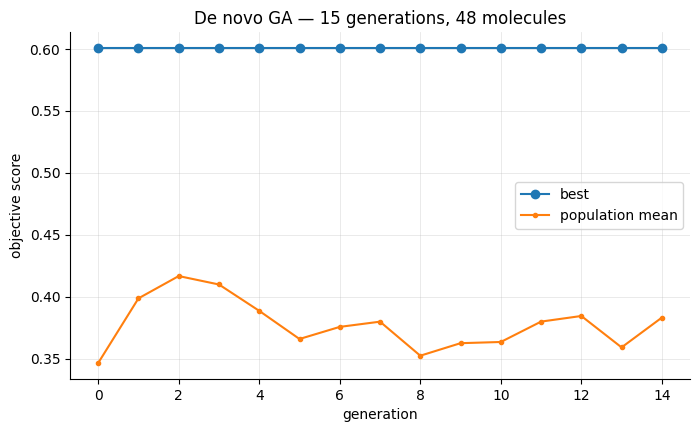

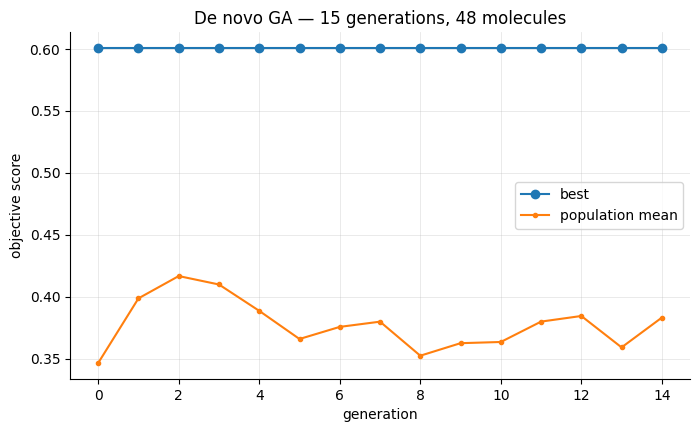

In [10]:
from pharmaml.viz import new_figure

print("top-8 de novo leaderboard (breakdown columns come free):")
print(ga_denovo.to_dataframe().head(8).to_string(index=False))

history = ga_denovo.history
fig_ga, ax_ga = new_figure(figsize=(8.0, 4.5))
ax_ga.plot([h["generation"] for h in history], [h["best_score"] for h in history],
           marker="o", label="best")
ax_ga.plot([h["generation"] for h in history], [h["mean_score"] for h in history],
           marker=".", label="population mean")
ax_ga.set(xlabel="generation", ylabel="objective score",
          title="De novo GA — 15 generations, 48 molecules")
ax_ga.legend()
fig_ga


### The Pareto front — what the blend hides

The leaderboard ranks by ONE number — the 0.5×QED + 0.25×LogP +
0.25×similarity blend. `pareto_front` re-reads the same run's
per-objective breakdown and extracts the molecules **no other candidate
dominates** — *a* dominates *b* iff *a* ≥ *b* on every objective and
strictly greater on at least one. The front is where the real trade-offs
live: a molecule can sit deep in the blended ranking and still be
unbeatable without paying for it on some objective.


Pareto front over 3 objectives [qed, logp_band, similarity]: 26 of 613 molecules non-dominated (0 excluded for non-finite values); strongest member 'CCOc1ccc(NC(C)=O)cc1' dominates 557 others

 rank                          smiles      qed  logp_band  similarity  dominates  crowding
    1            CCOc1ccc(NC(C)=O)cc1 0.770679   0.999046    0.219512        557  0.250456
    2          O=C(ONc1ccccc1)c1ccco1 0.778287   0.898152    0.232558        370  0.123349
    3   COc1ccc2[nH]c(CCNC(C)=O)cc2c1 0.844935   0.989557    0.169811        473  0.115214
    4           O=C(Nc1ccccc1)c1ccco1 0.784460   0.868091    0.219512        333  0.108941
    5           COc1cscc(NC(C)=O)cco1 0.820420   0.910712    0.187500        368  0.165004
    6    COc1cc2cc(CCNC(C)=O)[nH]c2s1 0.854626   0.996528    0.150943        485  0.135798
    7                CCNC(=O)c1ccccc1 0.676855   0.853100    0.277778        294  0.512030
    8          O=C(Nc1ccccc1)c1ccccc1 0.787491   0.643543    0.257143        19

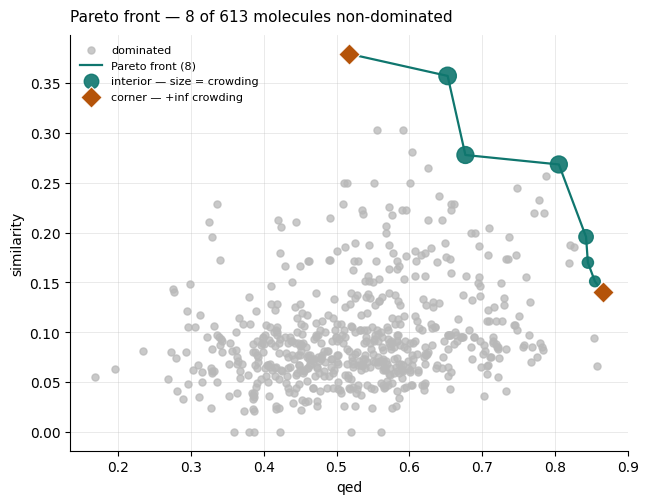

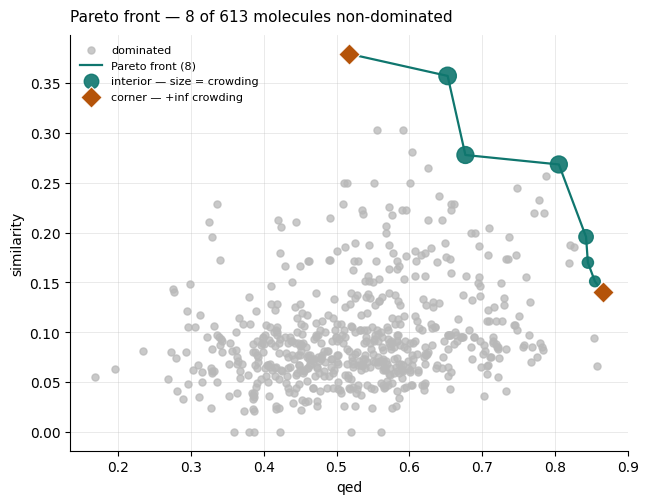

In [11]:
# the Pareto front of the de novo run -- what the blended ranking hides
from pharmaml.generative import pareto_front
from pharmaml.viz import plot_pareto_front

front = pareto_front(ga_denovo)
print(front)
print()
print(front.to_dataframe().to_string(index=False))

# the trade-off scatter: dominated molecules muted, the front connected.
# x/y pick a 2-objective projection of the 3-objective front above.
fig_pareto = plot_pareto_front(ga_denovo, x="qed", y="similarity")
fig_pareto


The front carries 26 of the 613 molecules. Its strongest member,
`CCOc1ccc(NC(C)=O)cc1` (dominating 557 others), is the leaderboard's
rank 1 — as it must be: anything dominating the blend's winner would
have outranked it. The story is the other end: the **deepest** front
member sits at leaderboard rank **197 of 613** — a molecule the blended
ranking buries, yet which cannot be improved on any objective without
sacrificing another. The scatter (qed × similarity) shows the shape of
the trade-off; note its title says **8** of 613, not 26 — plotting two
objectives projects the 3-objective front onto that pair (the same
semantics the CLI's `--pareto-plot` uses). The projection's trade-off
curve bends from the most aspirin-like survivor — rank 9,
`CC(=O)c1ccccc1`, similarity 0.379 — toward high-QED strangers the
corpus never saw. `pareto_front` is a pure, deterministic function of
any `MultiObjective` result; the CLI prints this audit with `--pareto`
and saves the scatter with `--pareto-plot`.


### Pruning the front — the crowding-distance shortlist

Twenty-six non-dominated molecules is already a lot to eyeball, and real
three-objective runs leave far more (a 300-molecule population over 30
generations measured **46 of 8,108**). Truncating by leaderboard rank
would drop the very corners the front exists to show. The NSGA-II
**crowding distance** ranks every member by its isolation in objective
space — the trade-off corners score `+inf`, crowded middles score low —
and `prune(k)` keeps the corners plus the most isolated interiors,
re-emitted in leaderboard order.


inf corners: 5 of 26
Pareto front over 3 objectives [qed, logp_band, similarity]: 26 of 613 molecules non-dominated (0 excluded for non-finite values); pruned to the 8 most isolated of 26 by crowding distance; strongest member 'COC1=Cc2cc(CNC(C)=O)[nH]c2C=CS1' dominates 386 others

 rank                          smiles      qed  logp_band  similarity  dominates  crowding
    1          O=C(Nc1ccccc1)c1ccccc1 0.787491   0.643543    0.257143        198  0.725246
    2                  CC(=O)c1ccccc1 0.517047   0.993880    0.379310        256       inf
    3 COC1=Cc2cc(CNC(C)=O)[nH]c2C=CS1 0.865224   0.952166    0.140351        386       inf
    4           O=C(c1ccccc1)c1ccccc1 0.652473   0.656393    0.357143        180  1.546628
    5         CCc1ccccccc(NC(C)=O)cc1 0.805119   0.411953    0.268293        114       inf
    6      O=C(Nc1ccccc1)C1=CSC=CC=C1 0.842433   0.415306    0.195652        111  0.931075
    7          CCCNS(=O)C1=COC=CC=CC1 0.775161   0.999825    0.075472        243

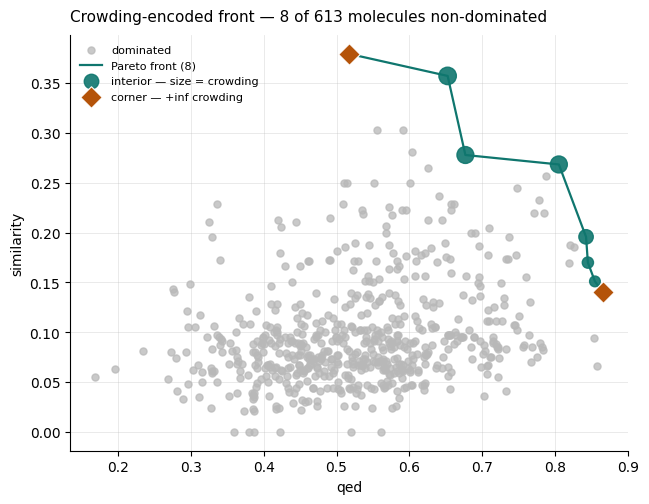

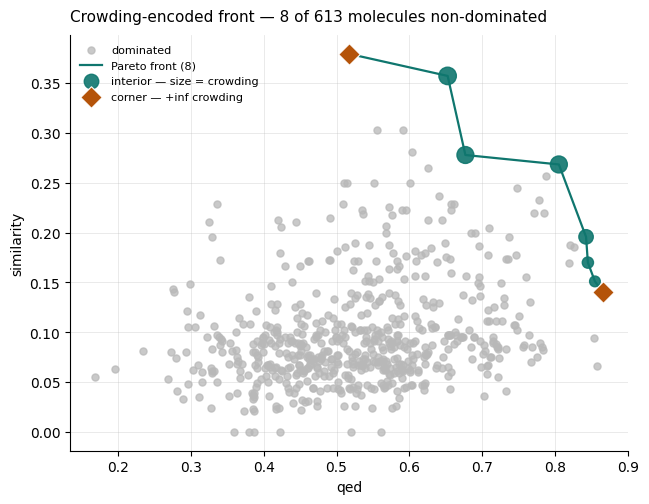

In [12]:
# crowding: +inf marks the boundary corners (best/worst on an objective),
# finite values the isolation of the interiors (bigger = more isolated)
distances = front.crowding_distance()
print("inf corners:", sum(1 for d in distances if d == float("inf")),
      "of", len(front))

# keep the corners + the most isolated interiors -- never a rank head,
# which would drop the very corners the front exists to show
shortlist = front.prune(8)
print(shortlist)
print()
print(shortlist.to_dataframe().to_string(index=False))

# the trade-off scatter, crowding-encoded: interior marker size = the
# pair's crowding, the +inf corners are amber diamonds (the same
# projection semantics as above -- the title says 8, the 2-objective
# projection of the 26-member 3-objective front)
fig_pruned = plot_pareto_front(ga_denovo, x="qed", y="similarity",
                               title="Crowding-encoded front")
fig_pruned


All five `+inf` corners survive — as do the three most isolated
interiors (crowding 1.55, 0.93, 0.73). Note what the cut teaches: the
front's strongest dominator (`CCOc1ccc(NC(C)=O)cc1`, 557 dominated
molecules) did **not** make the shortlist — it sits in a crowded region
of objective space. Dominating many molecules and being an isolated
trade-off anchor are different virtues, and the shortlist keeps the
second one. The summary line reports both numbers honestly: *26 of 613
non-dominated; pruned to the 8 most isolated of 26*. The selection is
deterministic and monotonic in `k` (a bigger keep extends, never
reshuffles); the CLI twin is `--pareto-keep N`.


## 5 · Seeded generation — start from your own molecules

The same optimiser, **seeded mode**: your molecules anchor generation 0 and
the search explores their neighbourhood (corpus molecules pad the rest of
the population, so your chemistry is explored *alongside* the corpus's
diversity — pass `corpus=seed_smiles` too for a strictly seed-isolated run).

One honest observation to expect below: when the objective itself
rewards similarity to a seed, the seed is already a strong local optimum —
the seeded run's best molecule may simply *be* your seed.

CLI equivalent:

```bash
pharmaml generative run --method ga --recipe similar --seeds examples/data/seed_molecules.csv
```


In [13]:
ga_seeded = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED
).optimize(seed_smiles=seed_smiles)

print(ga_seeded.summary())

pd.DataFrame(
    {
        "run": ["de novo", "seeded"],
        "best_score": [ga_denovo.best_score, ga_seeded.best_score],
        "best_smiles": [ga_denovo.best, ga_seeded.best],
        "unique": [len(ga_denovo), len(ga_seeded)],
        "elapsed_s": [ga_denovo.metadata["elapsed_s"], ga_seeded.metadata["elapsed_s"]],
    }
).round({"best_score": 3, "elapsed_s": 1})


genetic_algorithm: 613 unique molecule(s) from 15 iteration(s) in 1.7s -- best 'CC(=O)Oc1ccccc1C(=O)O' (score 0.699)


,run,best_score,best_smiles,unique,elapsed_s
0,de novo,0.601,CCOc1ccc(NC(C)=O)cc1,613,1.5
1,seeded,0.699,CC(=O)Oc1ccccc1C(=O)O,613,1.7


## 6 · Lead optimisation — scaffold-preserving mutation

`mutation="scaffold"` swaps the variation operator: instead of editing
characters (which routinely destroys ring systems), each offspring keeps its
parent's **Murcko framework verbatim** and resamples only the decorations.
The guarantee is structural, not lucky: a Murcko decoration is always
acyclic — any ring would be part of the framework — so re-attaching one
cannot change the scaffold. Acyclic parents (no framework to keep) fall
back to character mutation rather than stalling evolution.

The A/B below pins it down: both runs start from the same 12 seeds with the
corpus constrained to the seeds, then uniform mutation scrambles frameworks
while scaffold mode keeps every molecule on a seed scaffold.


In [14]:
from rdkit import RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold

RDLogger.DisableLog("rdApp.error")  # keep re-attachment noise out of the output

seed_frameworks = {
    MurckoScaffold.MurckoScaffoldSmilesFromSmiles(s) for s in seed_smiles
}
print(f"{len(seed_smiles)} seeds carry {len(seed_frameworks)} distinct Murcko frameworks")

runs = {}
for mode in ("scaffold", "uniform"):
    runs[mode] = GeneticOptimizer(
        objective, population_size=12, generations=12, seed=SEED, mutation=mode
    ).optimize(seed_smiles=seed_smiles, corpus=seed_smiles)

retention = pd.Series(
    {
        mode: sum(
            1
            for s in result.smiles
            if MurckoScaffold.MurckoScaffoldSmilesFromSmiles(s) in seed_frameworks
        )
        / len(result.smiles)
        for mode, result in runs.items()
    },
    name="fraction on a seed framework",
)
retention.round(3)


12 seeds carry 7 distinct Murcko frameworks


scaffold    1.000
uniform     0.505
Name: fraction on a seed framework, dtype: float64

The trade-off is visible in the scores: uniform mutation reaches higher
objective scores in this short run *because* it may leave the seed
frameworks entirely — scaffold mode spends its exploration budget inside
the chemistry you asked it to keep. The leaderboard's `murcko` column shows
exactly which seed framework each winner sits on.


In [15]:
ga_scaffold = runs["scaffold"]
scaffold_frame = ga_scaffold.to_dataframe().head(6).copy()
scaffold_frame["murcko"] = [
    MurckoScaffold.MurckoScaffoldSmilesFromSmiles(s) for s in scaffold_frame["smiles"]
]
print(f"scaffold mode: best {ga_scaffold.best_score:.3f} "
      f"(uniform mode: {runs['uniform'].best_score:.3f})")
scaffold_frame.round(3)


scaffold mode: best 0.699 (uniform mode: 0.774)


,rank,smiles,score,qed,logp_band,similarity,murcko
0,1,CC(=O)Oc1ccccc1C(=O)O,0.699,0.550,0.788,1.000,c1ccccc1
1,2,CC(C(=O)O)c1ccccc1C(=O)O,0.685,0.765,0.913,0.412,c1ccccc1
2,3,COc1ccccc1C(C)C(=O)O,0.680,0.772,0.993,0.361,c1ccccc1
3,4,CCN(CC)CC(=O)Nc1ccccc1C(=O)O,0.672,0.805,0.945,0.333,c1ccccc1
4,5,CC(C(=O)O)c1ccccc1C(C)C(=O)O,0.670,0.817,0.998,0.303,c1ccccc1
5,6,O=C(O)c1ccccc1Cl,0.667,0.676,0.999,0.433,c1ccccc1


## 6b · Scaffold hopping — cut two parents, recombine the fragments

`crossover="scaffold_hop"` is recombination with chemistry bookkeeping:
both parents are cut at *homologous* bonds — the join atoms match on
element, degree, aromaticity and formal charge — and recombined with
`Chem.molzip`. Six geometries compete for the draw: **bridge cuts**
(a pair of single acyclic bonds, fragments swapped cross-wise — every
ring system arrives intact, and whenever the parents' frameworks span
different fragments the child's Murcko scaffold differs from *both*
parents, Nicolaou et al.'s BREED tradition), the **ring-bond cuts**
below — merges, linker transplants, fused-ring splices — plus the
**ring insert**, a whole ring spliced into a cut acyclic bond as the
linker, and the **segment swap**, each parent's bounded acyclic middle
exchanged for the other's homologous middle (the bioisostere move:
an ester O for an amide N). The operator also works standalone —
`scaffold_hop_crossover(parent_a, parent_b, rng)` — for surgical use
outside the GA.


In [16]:
import random

from pharmaml.generative import GeneticOptimizer, scaffold_hop_crossover

# standalone: aspirin x naproxen, one homologous cut in each parent
draw = random.Random(0)
hybrid = scaffold_hop_crossover(seed_smiles[0], seed_smiles[9], draw)
print(f"parent A:  {seed_smiles[0]}   (aspirin)")
print(f"parent B:  {seed_smiles[9]}   (naproxen)")
print(f"hybrid:    {hybrid}\n")

# in the GA: framework recombination + decoration resampling together
ga_hop = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED,
    mutation="scaffold", crossover="scaffold_hop",
).optimize(seed_smiles=seed_smiles)
print(f"structural mode: {len(ga_hop)} unique, best {ga_hop.best_score:.3f}")
ga_hop.to_dataframe().head(5)[["smiles", "score", "rank"]]


parent A:  CC(=O)Oc1ccccc1C(=O)O   (aspirin)
parent B:  COc1ccc2cc(C(C)C(=O)O)ccc2c1   (naproxen)
hybrid:    COc1ccc2cc(C(C)C(=O)C(=O)c3ccccc3OC(C)=O)ccc2c1



[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31]

[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:31] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond


[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32]

[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32]

[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond
[15:19:32] Incomplete atom labelling, cannot make bond


... (2 outputs left out)

[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond


[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond
[15:19:33] Incomplete atom labelling, cannot make bond


structural mode: 495 unique, best 0.749


,smiles,score,rank
0,CCOc1ccccc1C(=O)O,0.748566,1
1,O=C(O)c1ccccc1Br,0.703119,2
2,CC(=O)Oc1ccccc1C(=O)O,0.698861,3
3,O=C(O)c1ccccc1OCCc1ccccc1,0.688547,4
4,CCc1ccccc1C(=O)O,0.685203,5


### Ring topology — the ring-bond cuts

Bridge cuts recombine fragment *arrangement*; ring topology needs its own
moves, and the operator has three ring-bond cuts plus one ring-piece
insertion into a cut acyclic bond (single ring bonds only — an aromatic
ring bond would make the re-zip invent bond orders, so those are never
cut):

* **merge** — both parents are cut at homologous single ring bonds and the
  two opened rings zip into *one* combined ring holding atoms from both
  (morpholine × piperidine below → a single 12-ring carrying both
  nitrogens and the oxygen);
* **transplant** — a two-ended linker — a single atom (acyclic, two
  single bonds, homologous flanks) or a whole contiguous acyclic *path*
  of up to four atoms — is excised from one parent and zipped into a
  cut ring bond of the other: ring homologation by one atom or a whole
  chain — the corpus benzodiazepinone's 7-ring below becomes an 8-ring
  oxazepinone with aspirin's ester oxygen, and the linker-path demo
  after it expands nicotine's pyrrolidine by cimetidine's `-CH2-S-`.

* **fuse** — a whole ring is excised from one parent — any ring
  attached to its molecule through exactly two single anchor bonds at
  two distinct ring atoms, aromatic ones included (the anchor bonds may
  themselves be ring bonds of an adjacent ring: that is what a fused
  system is) — and spliced across the other parent's opened ring bond:
  a fused or bridged bicyclic holding one ring from each parent, the
  full Nicolaou move set — the fused-ring demo after the linker paths
  splices the corpus diaryl ether's aryl ring into morpholine (a
  benzo-fused oxazocane) and metoprolol's para-phenylene across it (a
  bridged tricyclic);
* **insert** — the same two-anchor ring piece, but spliced INTO a cut
  *acyclic* bond of the other parent: both bridge halves re-join
  *through* the ring, which becomes the spacer — ring-as-linker, the
  {excised piece} × {cut type} matrix's last cell (the ring-insert
  demo after the fused splices puts ibuprofen's benzene into
  glycine's cut CH2-C(=O) bond, giving an aminomethylbenzoic acid).

The parents are looked up from the bundled corpus by SMILES value —
nothing is invented inline.


In [17]:
# ring topology recombination -- both geometries, corpus molecules only
def ring_sizes(smiles):
    """Ring-size profile (small ring first) for the demo prints."""
    mol = rdkit.Chem.MolFromSmiles(smiles)
    return sorted(len(r) for r in mol.GetRingInfo().AtomRings())

draw = random.Random(0)

# merge: two opened rings zip into ONE combined ring (atoms from both)
morpholine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1COCCN1")]
piperidine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1CCNCC1")]
merged = scaffold_hop_crossover(morpholine, piperidine, draw)
print(f"morpholine : {morpholine}   rings={ring_sizes(morpholine)}")
print(f"piperidine : {piperidine}   rings={ring_sizes(piperidine)}")
print(f"merged     : {merged}   rings={ring_sizes(merged)}  <- one 12-ring\n")

# transplant: a linker atom is excised from one parent and zipped into a
# cut ring bond of the other -- ring homologation
benzodiazepinone = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC1=NCC(=O)N(C)c2ccccc21")]
aspirin = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC(=O)Oc1ccccc1C(=O)O")]
transplanted = scaffold_hop_crossover(benzodiazepinone, aspirin, draw)
print(f"ring parent  : {benzodiazepinone}   rings={ring_sizes(benzodiazepinone)}")
print(f"linker donor : {aspirin}   (the ester O is a two-ended linker)")
print(
    f"transplanted : {transplanted}   rings={ring_sizes(transplanted)}"
    "  <- the 7-ring expanded to an 8-ring"
)


morpholine : C1COCCN1   rings=[6]
piperidine : C1CCNCC1   rings=[6]
merged     : C1CCNCCOCCNCC1   rings=[12]  <- one 12-ring

ring parent  : CC1=NCC(=O)N(C)c2ccccc21   rings=[6, 7]
linker donor : CC(=O)Oc1ccccc1C(=O)O   (the ester O is a two-ended linker)
transplanted : CC1=NCC(=O)N(C)c2ccccc2O1   rings=[6, 8]  <- the 7-ring expanded to an 8-ring


### Linker paths — multi-atom transplants

The transplant geometry also excises whole short chains: a contiguous
acyclic path of up to four atoms — an ethylene bridge, an oxyethylene
segment — is cut loose from its two hosts and zipped into a cut ring
bond of the other parent. Ring expansion by a whole linker, not just
one atom: the ring-size axis of scaffold morphing (piperidine →
azepane → azocane). Both demo parents are looked up from the bundled
corpus again — nothing invented inline.


In [18]:
# multi-atom linker paths -- ring expansion by a whole chain, corpus parents
draw = random.Random(0)

# nicotine's saturated pyrrolidine ring x cimetidine's -CH2-S- path:
# the 5-ring becomes a 7-ring carrying the transplanted sulfur
nicotine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CN1CCCC1c1cccnc1")]
cimetidine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CN=C(NC#N)NCCSCc1[nH]cnc1C")]
expanded = scaffold_hop_crossover(nicotine, cimetidine, draw)
print(f"ring parent   : {nicotine}   rings={ring_sizes(nicotine)}")
print(f"path donor    : {cimetidine}")
print(
    f"expanded      : {expanded}   rings={ring_sizes(expanded)}"
    "  <- the pyrrolidine gained cimetidine's -CH2-S-\n"
)

# lysine's -CH2-CH2- path: the same 5-ring becomes a 7-ring azepane
lysine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("NCCCCC(N)C(=O)O")]
homologated = scaffold_hop_crossover(nicotine, lysine, draw)
print(f"ring parent   : {nicotine}   rings={ring_sizes(nicotine)}")
print(f"path donor    : {lysine}  (the middle -CH2CH2-)")
print(
    f"homologated   : {homologated}   rings={ring_sizes(homologated)}"
    "  <- two methylenes longer"
)


ring parent   : CN1CCCC1c1cccnc1   rings=[5, 6]
path donor    : CN=C(NC#N)NCCSCc1[nH]cnc1C
expanded      : CN1CCSCCC1c1cccnc1   rings=[6, 7]  <- the pyrrolidine gained cimetidine's -CH2-S-

ring parent   : CN1CCCC1c1cccnc1   rings=[5, 6]
path donor    : NCCCCC(N)C(=O)O  (the middle -CH2CH2-)
homologated   : CN1CCCCCC1c1cccnc1   rings=[6, 7]  <- two methylenes longer


### Fused-ring splices — whole rings across the cut

The fourth geometry excises a whole ring from one parent — any ring
attached to its molecule through exactly two single anchor bonds,
aromatic ones included — and splices it across the other parent's
opened ring bond. The offspring is a fused or bridged ring system
holding one ring from each parent: the Nicolaou fused-ring move,
completing the BREED set. Both demo donors are looked up from the
bundled corpus again — nothing invented inline.


In [19]:
# fused-ring splices -- whole rings across the cut, corpus parents
draw = random.Random(0)

# the corpus diaryl ether's phenethylamine ring hangs off the rest of
# the molecule through two single anchor bonds (the ether O and the
# ethylamine CH2); spliced across morpholine's opened C-O bond it gives
# a benzo-fused oxazocane -- one ring from each parent
diaryl_ether = DEFAULT_CORPUS[DEFAULT_CORPUS.index("Cc1ccccc1Oc1ccccc1CCN(C)C")]
morpholine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1COCCN1")]
fused = scaffold_hop_crossover(diaryl_ether, morpholine, draw)
print(f"ring donor    : {diaryl_ether}   rings={ring_sizes(diaryl_ether)}")
print(f"ring parent   : {morpholine}   rings={ring_sizes(morpholine)}")
print(
    f"fused         : {fused}   rings={ring_sizes(fused)}"
    "  <- the aryl ring spliced across the morpholine cut\n"
)

# metoprolol's para-phenylene: the two anchors sit opposite each other,
# so BOTH benzene paths around the ring close independently -> a
# bridged tricyclic, not a simple bicycle
metoprolol = DEFAULT_CORPUS[DEFAULT_CORPUS.index("COCCc1ccc(OCC(O)CNC(C)C)cc1")]
bridged = scaffold_hop_crossover(metoprolol, morpholine, draw)
print(f"ring donor    : {metoprolol}   rings={ring_sizes(metoprolol)}")
print(f"ring parent   : {morpholine}   rings={ring_sizes(morpholine)}")
print(
    f"bridged       : {bridged}   rings={ring_sizes(bridged)}"
    "  <- para anchors: both benzene paths close independently"
)


ring donor    : Cc1ccccc1Oc1ccccc1CCN(C)C   rings=[6, 6]
ring parent   : C1COCCN1   rings=[6]
fused         : c1ccc2c(c1)CCNCCO2   rings=[6, 8]  <- the aryl ring spliced across the morpholine cut

ring donor    : COCCc1ccc(OCC(O)CNC(C)C)cc1   rings=[6]
ring parent   : C1COCCN1   rings=[6]
bridged       : c1cc2ccc1CCNCCO2   rings=[6, 10, 10]  <- para anchors: both benzene paths close independently


### Ring inserts — the ring becomes the linker

The fifth geometry completes the {excised piece} × {cut type} matrix:
the same two-anchor ring piece as the fused splice, but spliced INTO
a cut *acyclic* bond of the other parent — both bridge halves re-join
*through* the ring. The ring becomes the spacer: ring-as-linker. Both
demo parents are looked up from the bundled corpus again — nothing
invented inline.


In [20]:
# ring-as-linker inserts -- the ring becomes the spacer, corpus parents
draw = random.Random(20)

# ibuprofen's benzene (its two anchor hosts: the isobutyl CH2 and the
# acetic CH) is excised and spliced INTO glycine's cut CH2-C(=O) bond:
# the ring lands between glycine's amine and its acid -> an
# aminomethylbenzoic acid
ibuprofen = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC(C)Cc1ccc(C(C)C(=O)O)cc1")]
glycine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("NCC(=O)O")]
spliced = scaffold_hop_crossover(ibuprofen, glycine, draw)
print(f"ring donor  : {ibuprofen}   rings={ring_sizes(ibuprofen)}")
print(f"chain cut   : {glycine}  (the CH2-C(=O) bond)")
print(
    f"spliced     : {spliced}   rings={ring_sizes(spliced)}"
    "  <- the benzene between glycine's amine and acid\n"
)

# aspirin's benzene into ethyl acetate's cut O-C(=O) bond: the ester
# chain re-joined through the aryl spacer
aspirin = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC(=O)Oc1ccccc1C(=O)O")]
ethyl_acetate = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CCOC(C)=O")]
esterified = scaffold_hop_crossover(aspirin, ethyl_acetate, draw)
print(f"ring donor  : {aspirin}   rings={ring_sizes(aspirin)}")
print(f"chain cut   : {ethyl_acetate}  (the O-C(=O) bond)")
print(
    f"esterified  : {esterified}   rings={ring_sizes(esterified)}"
    "  <- the chain re-joined through the aryl spacer"
)


ring donor  : CC(C)Cc1ccc(C(C)C(=O)O)cc1   rings=[6]
chain cut   : NCC(=O)O  (the CH2-C(=O) bond)
spliced     : NCc1ccc(C(=O)O)cc1   rings=[6]  <- the benzene between glycine's amine and acid

ring donor  : CC(=O)Oc1ccccc1C(=O)O   rings=[6]
chain cut   : CCOC(C)=O  (the O-C(=O) bond)
esterified  : CCOc1ccccc1C(C)=O   rings=[6]  <- the chain re-joined through the aryl spacer


[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond


### Topology mutations — the single-parent ring-size moves

The crossover geometries recombine *two* parents;
`ring_topology_moves` is the single-parent counterpart — the
ring-size axis of scaffold morphing as a **mutation** (SAR 101): one
atom removed from a saturated ring with its neighbours rejoined
(**contraction** — piperidine → pyrrolidine, morpholine → pyrrolidine
/ tetrahydrofuran), or one methylene inserted into a saturated single
ring bond (**expansion** — piperidine → azepane). The same
conservative fences apply: aromatic and unsaturated rings are never
touched, fused/spiro atoms and shared bonds stay put, and the
ring-size window is 5–8. In the GA, `mutation="topology"` draws one
move per offspring (acyclic parents fall back to character mutation);
paired with the scaffold-hop crossover it completes the structural
move set — recombination *plus* ring-size mutation. Both demo parents
are looked up from the bundled corpus again — nothing invented
inline.


In [21]:
# ring-size mutations -- the single-parent medchem moves, corpus parents
from pharmaml.generative import ring_topology_moves, ring_topology_mutate

piperidine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1CCNCC1")]
morpholine = DEFAULT_CORPUS[DEFAULT_CORPUS.index("C1COCCN1")]
print(f"piperidine : {piperidine}")
print(f"  moves    : {ring_topology_moves(piperidine)}")
print(f"morpholine : {morpholine}")
print(f"  moves    : {ring_topology_moves(morpholine)}")

# the GA surface: one move drawn with the caller's rng (None -> fallback)
draw = random.Random(0)
print(f"\nmorpholine x Random(0) -> {ring_topology_mutate(morpholine, draw)}")

# in the GA: ring-size moves + scaffold-hop recombination together
ga_top = GeneticOptimizer(
    objective, population_size=48, generations=15, seed=SEED,
    mutation="topology", crossover="scaffold_hop",
).optimize(seed_smiles=seed_smiles)
print(f"topology mode: {len(ga_top)} unique, best {ga_top.best_score:.3f}")
ga_top.to_dataframe().head(5)[["smiles", "score", "rank"]]


piperidine : C1CCNCC1
  moves    : ['C1CCCC1', 'C1CCCNCC1', 'C1CCNC1']
morpholine : C1COCCN1
  moves    : ['C1CCNC1', 'C1CCOC1', 'C1CNCCOC1', 'C1COCN1']

morpholine x Random(0) -> C1COCN1


[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond


[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond


[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:34] Incomplete atom labelling, cannot make bond


[15:19:34] Incomplete atom labelling, cannot make bond
[15:19:35] Incomplete atom labelling, cannot make bond


[15:19:35] Incomplete atom labelling, cannot make bond
[15:19:35] Incomplete atom labelling, cannot make bond
[15:19:35] Incomplete atom labelling, cannot make bond
[15:19:35] Incomplete atom labelling, cannot make bond
[15:19:35] Incomplete atom labelling, cannot make bond


... (10 outputs left out)

[15:19:37] Incomplete atom labelling, cannot make bond
[15:19:37] Incomplete atom labelling, cannot make bond


[15:19:38] Incomplete atom labelling, cannot make bond


topology mode: 452 unique, best 0.749


,smiles,score,rank
0,CN1CCCCC1.O=COc1ccccc1C(=O)O,0.749033,1
1,CN1CCCCCC1.O=COc1ccccc1C(=O)O,0.739262,2
2,CN1CCCC1.O=COc1ccccc1C(=O)O,0.732309,3
3,CN1CCCCCCC1.O=COc1ccccc1C(=O)O,0.699739,4
4,CC(=O)Oc1ccccc1C(=O)O,0.698861,5


### Topology vs uniform — the ring-size A/B

§6 ran the classic A/B (scaffold-preserving vs uniform mutation,
framework retention); here is the ring-size twin, on an objective where
ring sizes are the whole game.  `RingSizeBandObjective` — a custom
`ScoringObjective`, §2's documented extension surface — bands the *mean
size of the saturated rings* (exactly the rings the topology moves act
on) around 7 members, and rides in a `MultiObjective` with the shipped
`QedObjective` and a lead-size `MolecularWeightBandObjective`: the
target is a drug-like molecule with a 7-membered saturated ring — the
azepane/oxazepane axis of scaffold morphing.  The two arms share the
seed, the corpus parents (the movable subset of the bundled corpus)
and every hyperparameter; only the mutation mode differs.  Watch the
population mean and the valid-offspring fraction: a topology move is
always a pre-sanitised molecule one ring-size step from its parent —
a character edit on a lead-sized SMILES is usually fatal.  Every
parent is looked up from the bundled corpus again — nothing invented
inline.


In [22]:
# a ring-rich objective: 7-membered saturated rings at lead size
import math

from rdkit import Chem

from pharmaml.generative import (
    MolecularWeightBandObjective,
    MultiObjective,
    QedObjective,
    ScoringObjective,
)


def sat_ring_sizes(mol):
    """Sizes of the fully-saturated single-bond rings -- the movable ones."""
    sizes = []
    for ring in mol.GetRingInfo().AtomRings():
        bonds = [
            mol.GetBondBetweenAtoms(ring[i], ring[(i + 1) % len(ring)])
            for i in range(len(ring))
        ]
        if all(
            b.GetBondType() == Chem.BondType.SINGLE and not b.GetIsAromatic()
            for b in bonds
        ):
            sizes.append(len(ring))
    return sizes


class RingSizeBandObjective(ScoringObjective):
    """Gaussian band on the mean size of the saturated rings."""

    name = "ring_size_band"

    def __init__(self, lo, hi):
        super().__init__()
        self.centre = (lo + hi) / 2.0
        self.sigma = max((hi - lo) / 2.0, 1e-6)

    def score(self, smiles):
        mol = self._parse(smiles)
        if mol is None:
            return 0.0
        sizes = sat_ring_sizes(mol)
        if not sizes:
            return 0.0  # nothing movable: a ring objective cannot be satisfied
        z = (sum(sizes) / len(sizes) - self.centre) / self.sigma
        return math.exp(-0.5 * z * z)


ring_objective = MultiObjective(
    [
        RingSizeBandObjective(6.0, 8.0),  # the 7-ring band
        QedObjective(),
        MolecularWeightBandObjective(220.0, 380.0),  # lead size
    ]
)

# the objective on the demo parent above, its one-step move set, and a
# lead-sized corpus parent (primidone) plus its 7-ring expansion
primidone = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CCC1(c2ccccc2)CNC(=O)NC1=O")]
expanded_primidone = next(
    m
    for m in ring_topology_moves(primidone)
    if sat_ring_sizes(Chem.MolFromSmiles(m)) == [7]
)
probe_rows = [("piperidine", piperidine)]
probe_rows += [
    (f"move -> {sat_ring_sizes(Chem.MolFromSmiles(m))}", m)
    for m in ring_topology_moves(piperidine)
]
probe_rows += [("primidone (218 Da)", primidone), ("move -> [7]", expanded_primidone)]
pd.DataFrame(
    [
        {
            "molecule": label,
            "smiles": smi,
            **{
                k: round(v, 3)
                for k, v in ring_objective.score_with_breakdown(smi)[1].items()
            },
            "total": round(ring_objective.score(smi), 3),
        }
        for label, smi in probe_rows
    ]
)


,molecule,smiles,ring_size_band,qed,mw_band,total
0,piperidine,C1CCNCC1,0.607,0.458,0.027,0.196
1,move -> [5],C1CCCC1,0.135,0.408,0.016,0.096
2,move -> [7],C1CCCNCC1,1.000,0.480,0.043,0.274
3,move -> [5],C1CCNC1,0.135,0.435,0.017,0.099
4,primidone (218 Da),CCC1(c2ccccc2)CNC(=O)NC1=O,0.607,0.783,0.593,0.655
5,move -> [7],CCC1(c2ccccc2)CCNC(=O)NC1=O,1.000,0.813,0.699,0.828


In [23]:
# the A/B: same objective, same seed, same corpus -- only the mutation differs
from collections import Counter

ring_parents = [s for s in DEFAULT_CORPUS if ring_topology_moves(s)]
print(f"{len(ring_parents)} corpus molecules carry a movable saturated ring")

topo_ab = {}
for mode in ("topology", "uniform"):
    topo_ab[mode] = GeneticOptimizer(
        ring_objective, population_size=12, generations=12, seed=SEED,
        mutation=mode,
    ).optimize(corpus=ring_parents)
    run = topo_ab[mode]
    print(f"{mode:9s}: best {run.best_score:.3f} ({len(run)} unique) -- {run.best}")

# ring-size census of each arm's top-12 elite: surgical vs broad
for mode, run in topo_ab.items():
    census = Counter()
    for smi in run.smiles[:12]:
        census.update(sat_ring_sizes(Chem.MolFromSmiles(smi)))
    print(f"{mode:9s} top-12 ring census: {dict(sorted(census.items()))}")

# trajectories side by side: best / population mean / offspring survival
history_ab = pd.DataFrame(
    {
        (mode, metric): [round(h[metric], 3) for h in run.history]
        for mode, run in topo_ab.items()
        for metric in ("best_score", "mean_score", "valid_offspring_fraction")
    }
)
history_ab.columns.names = ["mutation", "metric"]
history_ab


30 corpus molecules carry a movable saturated ring


topology : best 0.928 (82 unique) -- NCC1CCNC(c2ccccc2)(c2ccccc2)C(=O)N1


uniform  : best 0.872 (97 unique) -- C=S1C=NCCC2CCCNC(=O)C2=C2CC1CCON2
topology  top-12 ring census: {6: 5, 7: 7}
uniform   top-12 ring census: {5: 3, 6: 5, 7: 12, 8: 3}


mutation   topology                                        uniform                                    
metric   best_score mean_score valid_offspring_fraction best_score mean_score valid_offspring_fraction
0             0.482      0.240                    0.533      0.482      0.240                    0.084
1             0.774      0.362                    0.400      0.494      0.292                    0.082
2             0.928      0.526                    0.258      0.631      0.411                    0.107
3             0.928      0.583                    0.571      0.631      0.438                    0.103
4             0.928      0.780                    0.381      0.693      0.487                    0.160
5             0.928      0.815                    0.250      0.852      0.574                    0.063
6             0.928      0.745                    0.471      0.852      0.457                    0.082
7             0.928      0.719                    0.533      0.872      0.458                    0.163
8             0.928      0.827                    0.364      0.872      0.481                    0.065
9             0.928      0.838                    0.471      0.872      0.661                    0.085
10            0.928      0.779                    0.421      0.872      0.573                    0.094
11            0.928      0.802                    0.421      0.872      0.638                    0.094

The topology arm wins on every axis that matters: its best —
`NCC1CCNC(c2ccccc2)(c2ccccc2)C(=O)N1`, a drug-like lead built on a
7-membered ring — scores 0.928 and appears in generation 2; uniform
needs seven generations to reach 0.872, and its winner is an exotic
fused chimera that satisfies the objective's letter rather than its
spirit.  The population mean leads in all eleven generations after the
shared start (0.802 vs 0.638 at the end) and the valid-offspring
fraction runs about 4× higher (0.42 vs 0.10 averaged) — roughly nine in
ten character-edited offspring die before scoring.  The census line is
the surgical-vs-broad story in miniature: the topology elite are twelve
single-ring molecules spanning two ring sizes — one expansion step from
the corpus parents — while the uniform elite pack 23 rings across four
sizes.  Uniform *can* find 7-rings by luck; it just scatters, where
topology walks there.


### Adaptive operators — the GA that learns

The A/B above needed a human to read the tea leaves and pick the
winning operator family; `operator_selection="adaptive"` has the
optimiser make that call itself, in-run — the GA learns which
operators pay off. Three levels of operator choice (crossover vs
clone, the recombination geometry, the mutation family) draw through
credit-assigned softmaxes: each drawn operator earns
`(valid offspring ? score : 0) − mid-parent` on a sliding 20-attempt
window — failed operators are charged, not forgiven — and the next
draw is a softmax over that windowed credit with an exploration floor,
so a failing operator is demoted, never abandoned; one rng draw per
selection keeps an adaptive run exactly as deterministic as a fixed
one. The pair below re-runs the ring objective with the same seed,
objective and corpus parents as the A/B above — topology mutation in
both arms, only the operator selection differs — on a slightly longer
budget (16 × 16 rather than 12 × 12) so the credit window has runway
to learn. And the learning is not a black box: the adaptive result's
`metadata["operator_stats"]` carries, per level and operator, the
draws, the surviving offspring and the final selection probability.


In [24]:
# the adaptive A/B: same objective, seed and corpus parents as above
# (topology mutation in both arms) -- only the operator selection
# differs; the credit needs a slightly longer run to learn
aos_ab = {}
for sel in ("uniform", "adaptive"):
    aos_ab[sel] = GeneticOptimizer(
        ring_objective, population_size=16, generations=16, seed=SEED,
        mutation="topology", operator_selection=sel,
    ).optimize(corpus=ring_parents)

# best / final population mean: the two arms above, then the fresh pair
for label, run in [
    ("topology (above)", topo_ab["topology"]),
    ("uniform (above)", topo_ab["uniform"]),
    ("fixed ops (16/16)", aos_ab["uniform"]),
    ("adaptive (16/16)", aos_ab["adaptive"]),
]:
    print(
        f"{label:19s}: best {run.best_score:.3f} ({len(run)} unique) "
        f"-- {run.best} | final mean {run.history[-1]['mean_score']:.3f}"
    )

# the introspection artifact: what the GA learned about its own operators
stats = aos_ab["adaptive"].metadata["operator_stats"]
operator_frame = pd.DataFrame(
    [
        {
            "level": level,
            "operator": op,
            "draws": entry["draws"],
            "successes": entry["successes"],
            "final_probability": round(entry["final_probability"], 3),
        }
        for level, table in stats.items()
        for op, entry in table.items()
    ]
)
operator_frame


topology (above)   : best 0.928 (82 unique) -- NCC1CCNC(c2ccccc2)(c2ccccc2)C(=O)N1 | final mean 0.802
uniform (above)    : best 0.872 (97 unique) -- C=S1C=NCCC2CCCNC(=O)C2=C2CC1CCON2 | final mean 0.638
fixed ops (16/16)  : best 0.961 (155 unique) -- O=C1CCC(=O)NC(c2ccccc2)(c2ccccc2)C1 | final mean 0.765
adaptive (16/16)   : best 0.966 (147 unique) -- O.O=C1CCCNC(c2ccccc2)(c2ccccc2)C1 | final mean 0.808


,level,operator,draws,successes,final_probability
0,level1,crossover,40,6,0.107
1,level1,clone,246,210,0.893
2,geometry,splice,40,6,1.000
3,mutation,topology,243,211,0.896
4,mutation,character,43,4,0.104


The GA re-derived §6b's verdict inside a single run. The mutation
family's row is that conclusion in miniature: 243 topology draws kept
211 offspring (87 % survival — a topology move is a pre-sanitised
molecule one ring step from its parent) against 43 character draws
that kept 4, and the final selection probability settles at 0.896 for
topology vs 0.104 for character. Level 1 learned the same lesson about
the character splice: cloning survived 210 of 246 draws (p 0.893)
where the splice crossover kept 6 of 40 — so the run spends its
attempts on clone-then-topology-mutate, exactly the §6b-winning
recipe, while the geometry row is bookkeeping only (the splice
crossover has a single geometry, p 1.000 by construction). The
exploitation shows at the scoreboard: the adaptive arm closes at
population mean 0.808 vs 0.765 for the fixed-operator control, ahead
in 13 of the 16 generations, with best 0.966 in generation 11 against
the control's 0.961, which arrives only in the final generation. Both
winners are on-target 7-membered lactams; the adaptive arm's
`O.O=C1CCCNC(c2ccccc2)(c2ccccc2)C1` carries a hitchhiking water
molecule — QED quietly forgives the extra fragment, the objective's
letter over its spirit again.


mutation mix at generation  0: {'topology': 0.5, 'character': 0.5}
mutation mix at generation 15: {'topology': 0.8964223618089852, 'character': 0.10357763819101498}


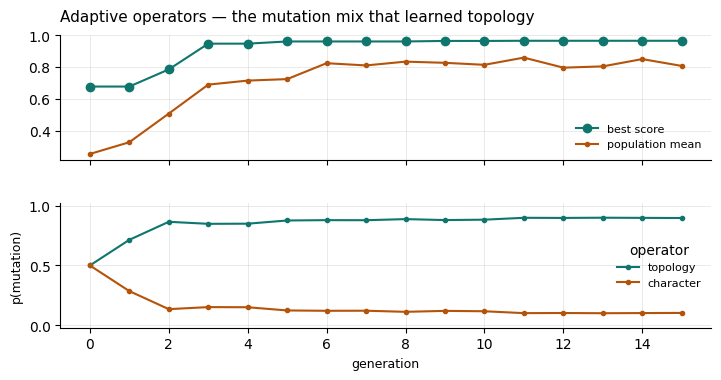

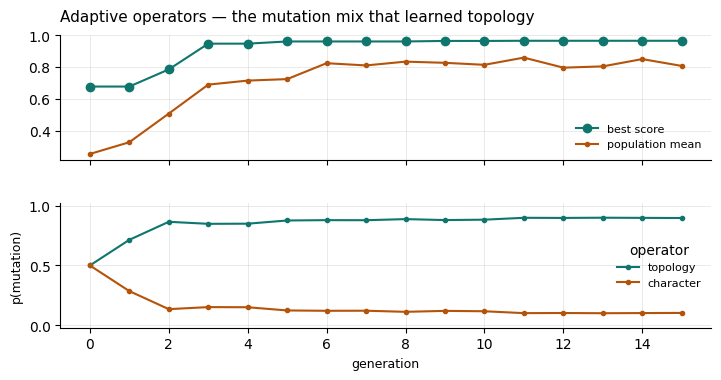

In [25]:
# the learning curve of the adaptive run above -- score panel + mutation mix
from pharmaml.viz import plot_operator_trajectory

traj = aos_ab["adaptive"].metadata["operator_trajectory"]
print("mutation mix at generation  0:", traj[0]["mutation"])
print("mutation mix at generation 15:", traj[-1]["mutation"])

fig_aos = plot_operator_trajectory(
    aos_ab["adaptive"],
    title="Adaptive operators — the mutation mix that learned topology",
)
fig_aos


The operator trajectory is the learning itself, on one pair of shared
axes. The run starts exactly fair — generation 0's printed record is
`{'topology': 0.5, 'character': 0.5}`, no operator favoured — and a
single generation of windowed credit is enough to flip the balance:
topology's share is already 0.714 at generation 1 and 0.865 at
generation 2, exactly as the population mean doubles from 0.255 to
0.509. From there the mix holds a 0.85–0.90 plateau while the mean
climbs on to its 0.808 close — the two panels move together because
the mix shift *buys* the mean climb — and the best score's 0.966
lands in generation 11, inside the learned regime rather than by luck
at the close. The closing record, `{'topology': 0.8964223618089852,
'character': 0.10357763819101498}`, is the full-precision twin of the
tidy table above: its 0.896 / 0.104 final-probability row differs from
the record only by rounding (the stats carry four decimals, the frame
three). The default figure shows the mutation level — the flagship
story; pass all three `levels` to add level 1's parallel takeover
(clone 0.5 → 0.893, the same lesson) and the degenerate geometry line
at p 1.000.


### Segment swaps — the bioisostere exchange

The sixth geometry is two-point crossover, the graph analogue of
classic GA recombination: each parent's bounded acyclic *middle* — a
single atom or a contiguous path of up to four atoms — is excised from
the flank parent and REPLACED by the other parent's homologous middle
(the flanking environments must match, direct or flipped, so each seam
bonds signature-matched atoms).  It is the only size-conserving
geometry — insert grows a recipient, swap exchanges in place — and it
is the medchem **bioisostere** move: an ester oxygen exchanged for an
amide nitrogen, an ether O for a thioether S.  Aspirin × paracetamol
crosses exactly there: the ester and the amide sit in homologous
environments (both flanked by a carbonyl carbon and an aryl carbon),
so the swap yields salicylamide — a real molecule that is neither
parent.  At corpus scale the exchange space is wide: across the bundled
244 molecules the swap scan admits 7,328 candidates over 295 distinct
linker chemistries — 1,738 heteroatom bioisostere exchanges (O↔N 153
each way, the ester/amide class above), 1,438 conservative C→C, and
N↔C 368 each way.  Both demo parents are looked up from the bundled
corpus again — nothing invented inline.


In [26]:
# two-point segment swaps -- the linker / bioisostere exchange, corpus parents
from pharmaml.generative import scaffold_hop_crossover

aspirin = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC(=O)Oc1ccccc1C(=O)O")]
paracetamol = DEFAULT_CORPUS[DEFAULT_CORPUS.index("CC(=O)Nc1ccc(O)cc1")]
print(f"parent A:  {aspirin}   (aspirin)")
print(f"parent B:  {paracetamol}   (paracetamol)")

# the ester O and the amide N sit in homologous environments: the swap
# crosses them -- seed 0 lands the salicylamide child, seed 5 the twin
first = scaffold_hop_crossover(aspirin, paracetamol, random.Random(0))
second = scaffold_hop_crossover(aspirin, paracetamol, random.Random(5))
print(f"seed 0 ->  {first}   (salicylamide: neither parent)")
print(f"seed 5 ->  {second}   (the O-for-N twin)")

# in the GA the geometry joins the merged candidate pool invisibly:
# no GeneticOptimizer change, the draw just has one more move class


parent A:  CC(=O)Oc1ccccc1C(=O)O   (aspirin)
parent B:  CC(=O)Nc1ccc(O)cc1   (paracetamol)
seed 0 ->  CC(=O)Nc1ccccc1C(=O)O   (salicylamide: neither parent)
seed 5 ->  CC(=O)Oc1ccc(O)cc1   (the O-for-N twin)


[15:19:44] Incomplete atom labelling, cannot make bond
[15:19:44] Incomplete atom labelling, cannot make bond


## 7 · Reinforcement learning — a prior that writes SMILES, then a policy that bends it

`ReinventOptimizer` is the REINVENT-style pipeline, in two acts:

1. **Prior** — `SmilesRnn`, a character-level GRU trained on the corpus:
   it learns the *grammar* of drug-like SMILES (which characters follow
   which), nothing about the objective yet;
2. **Fine-tuning** — the same network becomes the *policy*: REINFORCE with
   a running baseline (the score advantage), an entropy bonus (don't
   collapse onto one spelling), a prior anchor (don't drift into
   un-chemical strings), and experience replay. The objective is the
   reward.

Honest scope: this is a compact, CPU-sized implementation of the REINVENT
*recipe* — not a replication of the full AstraZeneca stack.


char-GRU prior: 8 epochs, loss 2.62 -> 1.11


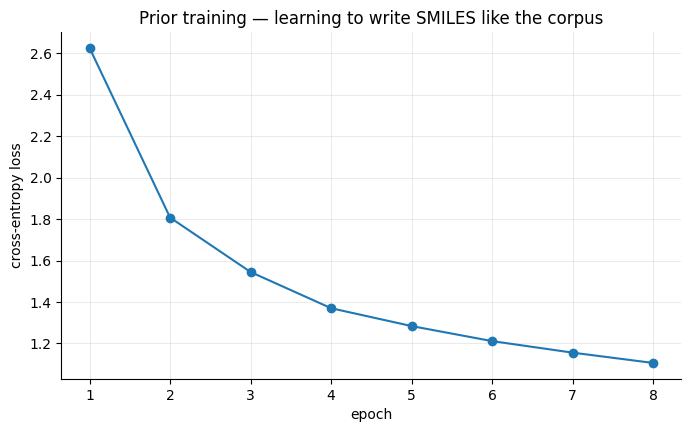

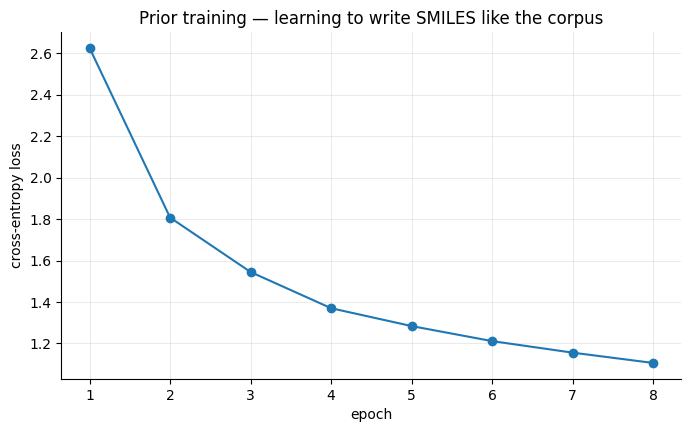

In [27]:
from pharmaml.generative import SmilesRnn

prior = SmilesRnn(hidden_dim=96, seed=SEED)
losses = prior.train_prior(DEFAULT_CORPUS, epochs=8)
print(f"char-GRU prior: {len(losses)} epochs, loss {losses[0]:.2f} -> {losses[-1]:.2f}")

fig_prior, ax_prior = new_figure(figsize=(8.0, 4.5))
ax_prior.plot(range(1, len(losses) + 1), losses, marker="o")
ax_prior.set(xlabel="epoch", ylabel="cross-entropy loss",
             title="Prior training — learning to write SMILES like the corpus")
fig_prior


With the prior trained, fine-tune it toward the §3 objective. A score
plateau triggers the built-in early stop — RL runs until it stops
improving, not until the iteration budget burns out (this run kept
improving to the final iteration, so the stop never fired).


In [28]:
from pharmaml.generative import ReinventOptimizer

rl = ReinventOptimizer(
    objective, prior=prior, iterations=15, batch_size=32, seed=SEED
).optimize()

print(rl.summary())
print(f"early stopped   : {rl.metadata['early_stopped']} (mean-score plateau)")
print(f"unique output   : {len(rl)} molecules in {rl.metadata['elapsed_s']:.1f} s")


reinforce_rl: 107 unique molecule(s) from 15 iteration(s) in 0.7s -- best 'CC(=O)CCc1ccccc1' (score 0.601)
early stopped   : False (mean-score plateau)
unique output   : 107 molecules in 0.7 s


The RL history carries the mean batch score and the best-so-far curve per
iteration — the classic REINVENT diagnostic pair.


top-6 RL leaderboard:
 rank                smiles    score      qed  logp_band  similarity
    1      CC(=O)CCc1ccccc1 0.600976 0.641895   0.978560    0.323529
    2 CC(=O)C(=O)CCc1ccccc1 0.598053 0.655116   0.975507    0.305556
    3          CCOc1ccccc1O 0.597255 0.674684   0.978376    0.285714
    4       CC(=O)Cc1ccccc1 0.591929 0.602575   0.983592    0.343750
    5  CC(=O)C(=O)Cc1ccccc1 0.570790 0.629170   0.828812    0.323529
    6        CC(=O)c1ccccc1 0.563439 0.517047   0.993880    0.379310


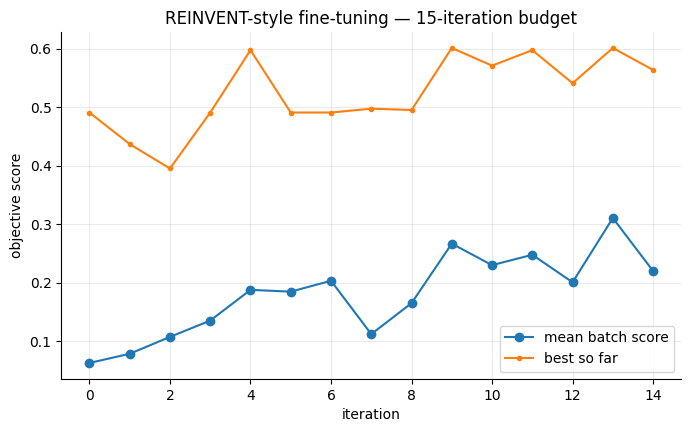

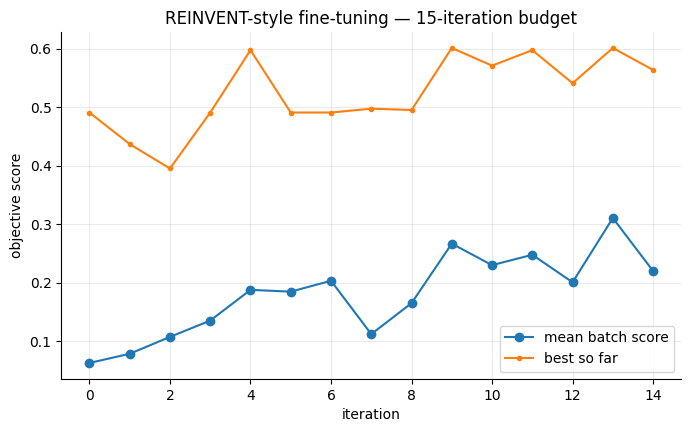

In [29]:
rl_history = pd.DataFrame(rl.history)

fig_rl, ax_rl = new_figure(figsize=(8.0, 4.5))
ax_rl.plot(rl_history["iteration"], rl_history["mean_score"],
           marker="o", label="mean batch score")
ax_rl.plot(rl_history["iteration"], rl_history["best_score"],
           marker=".", label="best so far")
ax_rl.set(xlabel="iteration", ylabel="objective score",
          title="REINVENT-style fine-tuning — 15-iteration budget")
ax_rl.legend()

print("top-6 RL leaderboard:")
print(rl.to_dataframe().head(6).to_string(index=False))
fig_rl


## 8 · Novelty — the anti-rediscovery recipe

Rediscovering the corpus is the failure mode of pure similarity search:
the "best" molecule is just a corpus member re-spelled. `NoveltyObjective`
(`1 − max` Tanimoto vs the corpus) makes rediscovery score exactly 0 —
pair it with QED so the search stays drug-like *while* leaving the corpus.

The honest trade-off, visible right in the output: unconstrained novelty
rewards strange chemistry (exotic sulfide rings below) — the weight vector
is your dial between "safe and similar" and "new and weird".


In [30]:
novelty_objective = MultiObjective(
    [QedObjective(), NoveltyObjective()], weights=[0.5, 0.5]
)
ga_novel = GeneticOptimizer(
    novelty_objective, population_size=48, generations=15, seed=SEED
).optimize()

print(ga_novel.summary())
ga_novel.to_dataframe().head(6).round(3)


genetic_algorithm: 635 unique molecule(s) from 15 iteration(s) in 1.4s -- best 'OCC1CCCPCCC1SC1CCPSC1' (score 0.838)


,rank,smiles,score,qed,novelty
0,1,OCC1CCCPCCC1SC1CCPSC1,0.838,0.803,0.875
1,2,OCC1CCCPCCCC1SC1CCSC1,0.838,0.805,0.872
2,3,OCCC1CC=NPCCSCPCSC1,0.835,0.795,0.878
3,4,OCC1CCCPC=C1SC1CCPS1,0.835,0.796,0.875
4,5,CC1NPCC=CN=C=C1PSCF,0.834,0.779,0.894
5,6,OC=C(NC1=CN=CC=CSC1)C1=CC=CC=CCC=C1,0.834,0.769,0.903


## 9 · GA vs RL — same objective, same seed, head-to-head

Four arms, one objective, one seed: the de novo GA (character-splice
crossover), the seeded GA, the same GA in **structural mode** (§6b's
scaffold-preserving mutation plus the six-geometry scaffold-hop
crossover — every candidate is a framework recombination with real
ring chemistry), and the RL policy. The optimisers are complementary,
not competing: the GA explores a wide combinatorial space cheaply; the
structural GA searches the narrower space of framework
recombinations; RL trains a *policy* that can then generate on its
own. On this objective and budget the numbers land where they land —
the interesting lines are the last two: whether the searches even
visit the same molecules, and whether framework-constrained
recombination gives up anything against unconstrained character
splicing.

CLI twins (the seeded arm takes `--seeds your_table.csv`):

```bash
pharmaml generative run --method ga --recipe druglike --iterations 20 --seed 42
pharmaml generative run --method ga --recipe druglike --scaffold --scaffold-hop --iterations 15 --seed 42
pharmaml generative run --method rl --recipe druglike --iterations 15 --out molecules.csv
```


In [31]:
methods = pd.DataFrame(
    {
        "method": ["ga (de novo)", "ga (seeded)", "ga (structural)", "rl"],
        "best_score": [
            ga_denovo.best_score,
            ga_seeded.best_score,
            ga_hop.best_score,
            rl.best_score,
        ],
        "best_smiles": [ga_denovo.best, ga_seeded.best, ga_hop.best, rl.best],
        "unique": [len(ga_denovo), len(ga_seeded), len(ga_hop), len(rl)],
        "elapsed_s": [
            ga_denovo.metadata["elapsed_s"],
            ga_seeded.metadata["elapsed_s"],
            ga_hop.metadata["elapsed_s"],
            rl.metadata["elapsed_s"],
        ],
    }
)
print(methods.to_string(index=False))

overlap = set(ga_denovo.smiles[:10]) & set(rl.smiles[:10])
print(f"\ntop-10 overlap GA (de novo) vs RL: "
      f"{overlap or 'none — two searches, different corners'}")
overlap_structural = set(ga_hop.smiles[:10]) & set(ga_denovo.smiles[:10])
print(f"top-10 overlap GA (structural) vs GA (de novo): "
      f"{overlap_structural or 'none — recombination, other molecules'}")


         method  best_score           best_smiles  unique  elapsed_s
   ga (de novo)    0.600755  CCOc1ccc(NC(C)=O)cc1     613   1.545450
    ga (seeded)    0.698861 CC(=O)Oc1ccccc1C(=O)O     613   1.704953
ga (structural)    0.748566     CCOc1ccccc1C(=O)O     495   2.935445
             rl    0.600976      CC(=O)CCc1ccccc1     107   0.709628

top-10 overlap GA (de novo) vs RL: {'CC(=O)c1ccccc1'}
top-10 overlap GA (structural) vs GA (de novo): none — recombination, other molecules


## 10 · Publish — the leaderboard and the one-click bundle

Every run's leaderboard concatenates into one ranked table (method column
attached), the CSV lands in `WORK`, and `save_visual_bundle` publishes the
four inline figures + tables + headline metrics as a shareable
report directory — the same call the other four workflow notebooks end on.


In [32]:
from pharmaml.viz import save_visual_bundle

leaderboard = pd.concat(
    [
        ga_denovo.to_dataframe().assign(method="ga_de_novo"),
        ga_seeded.to_dataframe().assign(method="ga_seeded"),
        ga_novel.to_dataframe().assign(method="ga_novel"),
        rl.to_dataframe().assign(method="rl"),
    ],
    ignore_index=True,
)
leaderboard.to_csv(WORK / "generative_leaderboard.csv", index=False)
print(f"leaderboard: {len(leaderboard)} rows -> {WORK / 'generative_leaderboard.csv'}")

artifacts = save_visual_bundle(
    figures={
        "corpus_landscape": fig_landscape,
        "ga_convergence": fig_ga,
        "prior_training": fig_prior,
        "rl_finetuning": fig_rl,
        "aos_trajectory": fig_aos,
        "pareto_front": fig_pareto,
        "pareto_pruned": fig_pruned,
    },
    tables={"leaderboard": leaderboard.head(50), "methods": methods},
    metrics={
        "best_score_ga": ga_denovo.best_score,
        "best_score_rl": rl.best_score,
        "corpus_size": len(DEFAULT_CORPUS),
    },
    out_dir=WORK / "report",
    title="Molecule generation workflow — GA + RL on a curated corpus",
    subtitle=(f"QED + LogP + similarity objective · {len(leaderboard)} "
              f"ranked molecules · seed {SEED}"),
    formats=("png", "svg"),
    close=True,   # figures already rendered inline above; free the memory
)
for path in artifacts:
    print(f"  {path.relative_to(WORK)}")


leaderboard: 1968 rows -> /tmp/generative_workflow_x817ead4/generative_leaderboard.csv


  report/report.html
  report/leaderboard.csv
  report/leaderboard.md
  report/methods.csv
  report/methods.md
  report/corpus_landscape.png
  report/corpus_landscape.svg
  report/ga_convergence.png
  report/ga_convergence.svg
  report/prior_training.png
  report/prior_training.svg
  report/rl_finetuning.png
  report/rl_finetuning.svg
  report/aos_trajectory.png
  report/aos_trajectory.svg
  report/pareto_front.png
  report/pareto_front.svg
  report/pareto_pruned.png
  report/pareto_pruned.svg


## 11 · Recap

One notebook, the full molecule-building story:

* **Corpus** — 244 curated drug-like SMILES, validated in place (§1);
* **Objectives** — seven ready-made scores: four property bands + QED,
  similarity, pharmacophore, novelty (§2);
* **Multi-objective** — weighted geometric mean where one zero vetoes the
  molecule (§3);
* **De novo GA** — 613 unique molecules in seconds, per-generation history,
  free breakdown columns and the Pareto front of what the blend hides
  — 26 of the 613 non-dominated, the deepest at leaderboard rank 197,
  pruned to the 8 most isolated by crowding distance (the corners
  always survive) — two figure twins included (§4);
* **Seeded GA** — your own molecules anchor the search (§5);
* **Lead optimisation** — scaffold-preserving mutation kept 100 % of the
  run on seed frameworks vs 50.5 % for uniform mutation (§6);
* **Scaffold hopping** — the six-geometry BREED crossover (bridge,
  merge, transplant, fuse, insert, swap) plus the single-parent
  ring-size topology mutations (§6b);
* **Ring-size A/B** — topology vs uniform mutation, same seed and
  parents, only the operator differs: best 0.928 in generation 2 vs
  0.872 in generation 7, population mean ahead in every generation,
  ~4× the offspring survival (§6b);
* **Adaptive operators** — the GA re-derives that verdict in-run:
  `operator_selection="adaptive"` on the same ring objective pushes the
  topology family to final probability 0.896 (211 of 243 draws kept)
  and closes at population mean 0.808 vs the fixed-operator control's
  0.765 — and its learning curve is now a one-call figure,
  `plot_operator_trajectory` (§6b);
* **RL** — a char-GRU prior learned the corpus grammar, then REINVENT-style
  fine-tuning bent it toward the objective; the plateau early-stop stayed
  armed but never fired — the mean score improved to the last iteration
  (§7);
* **Novelty** — the anti-rediscovery recipe, honestly showing its
  strange-chemistry trade-off (§8);
* **GA vs RL** — same objective, same seed, four arms head-to-head:
  de novo GA, seeded GA, structural-mode GA and the RL policy (§9);

* **Publish** — leaderboard CSV + one-click visual bundle (§10).

Where to go next:

* the runnable script twin: `examples/run_generative_design.py` (~10 s);
* the CLI: `pharmaml generative run --method ga|rl --recipe
  qed|logp|druglike|similar|novel` (+ `--scaffold`, `--scaffold-hop`, `--topology`, `--seeds`);
* the README's generative section for the scope notes (what the RL is and
  is not, what scaffold mode guarantees).
